In [16]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:
raw_train_df = pd.read_csv("../data/train.csv")
test_df = pd.read_csv("../data/test.csv")

## Data Dictionary
From the [Kaggle page for the dataset](https://www.kaggle.com/competitions/titanic/data). The "Variable", "Definition", and "Key" columns are directly from the page, while the "Datatype" and "Immediately Excluded?" columns are for my own notes.
| Variable | Definition                                 | Key                                            | Datatype                     | Immediately Excluded?
|----------|--------------------------------------------|------------------------------------------------| ---------------------------- | ---------
| survival | Survival                                   | 0 = No, 1 = Yes                                | bool (target variable)       | N/A
| pclass   | Ticket class                               | 1 = 1st, 2 = 2nd, 3 = 3rd                      | Categorical                  | N
| sex      | Sex                                        |                                                | Categorical                  | N
| Age      | Age in years                               |                                                | Numerical                    | N
| sibsp    | # of siblings / spouses aboard the Titanic |                                                | Numerical                    | N
| parch    | # of parents / children aboard the Titanic |                                                | Numerical                    | N
| ticket   | Ticket number                              |                                                | String (unused ID)           | Y
| fare     | Passenger fare                             |                                                | Numerical                    | N
| cabin    | Cabin number                               |                                                | Categorical (requires 1-hot) | Y (~75% null values, with way too many unique categorical values to be worth encoding)
| embarked | Port of Embarkation                        | C = Cherbourg, Q = Queenstown, S = Southampton | Categorical (requires 1-hot) | N


In [3]:
raw_train_df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
raw_train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
raw_train_df.nunique()

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

In [6]:
raw_train_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


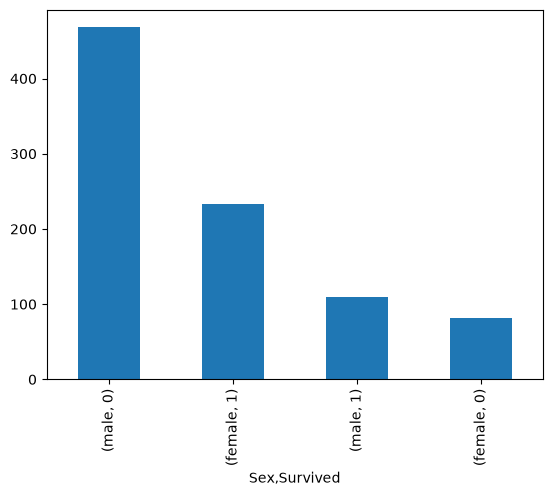

In [7]:
raw_train_df[["Sex", "Survived"]].value_counts().plot.bar(x="Sex", y="Survived")
plt.show()

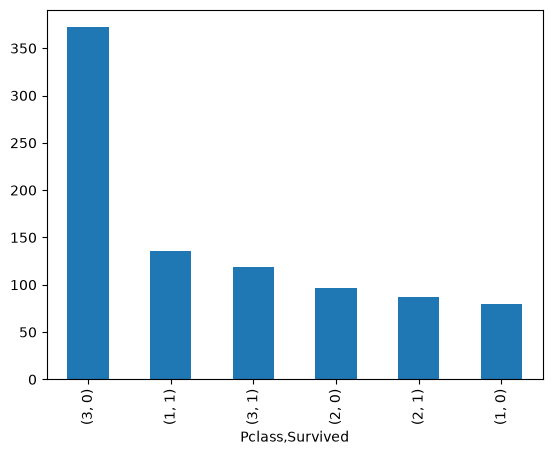

In [8]:
raw_train_df[["Pclass", "Survived"]].value_counts().plot.bar(x="Sex", y="Survived")
plt.show()

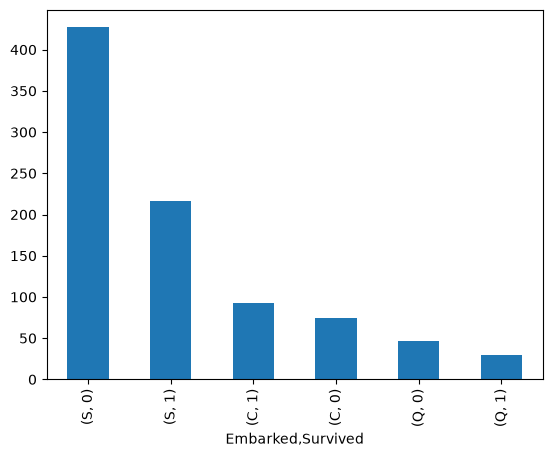

In [9]:
raw_train_df[["Embarked", "Survived"]].value_counts().plot.bar(x="Sex", y="Survived")
plt.show()

In [10]:
#TODO: Fare vs. Survival, Pclass vs. Fare 
# raw_train_df[][["Fare", "Survived"]].plot.hist(x="Fare", y="Survived")

In [18]:
train_df = raw_train_df[["Survived", "PassengerId", "Sex", "Pclass", "Age", "SibSp", "Parch", "Fare", "Embarked"]].set_index("PassengerId").copy()

train_df["Sex"] = train_df["Sex"].apply(lambda x: 1 if x.lower() == "male" else 0)

embarked_encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
embarked_cols = embarked_encoder.fit_transform(train_df[["Embarked"]]).drop(columns=["Embarked_nan"])
train_df = train_df.drop(columns=["Embarked"]).join(embarked_cols)

pclass_encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
pclass_cols = pclass_encoder.fit_transform(train_df[["Pclass"]])
train_df = train_df.drop(columns=["Pclass"]).join(pclass_cols)

age_imputer = imputer_transformer = ColumnTransformer(
    transformers=[
        ('impute_nums', IterativeImputer(random_state=93), ["Age"])
    ],
    remainder='passthrough'
).set_output(transform="pandas")
X = train_df.drop(columns=["Survived"])
# col_names = X.columns
y = train_df["Survived"]
X = age_imputer.fit_transform(X)
X.columns = [c.replace("impute_nums__", "").replace("remainder__", "") for c in X.columns]

scaler = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), ["Age", "Fare"])
    ],
    remainder='passthrough'
).set_output(transform="pandas")

X = scaler.fit_transform(X)
X.columns = [c.replace("scaler__", "").replace("remainder__", "") for c in X.columns]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=93) #TODO: stratified k-fold
X_train.head()

,Age,Fare,Sex,SibSp,Parch,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
PassengerId,,,,,,,,,,,
471,0.000000,-0.502445,1,0,0,0.0,0.0,1.0,0.0,0.0,1.0
78,0.000000,-0.486337,1,0,0,0.0,0.0,1.0,0.0,0.0,1.0
276,2.562648,0.921244,0,1,0,0.0,0.0,1.0,1.0,0.0,0.0
711,-0.438572,0.348330,0,0,0,1.0,0.0,0.0,1.0,0.0,0.0
80,0.023154,-0.397241,0,0,0,0.0,0.0,1.0,0.0,0.0,1.0


In [13]:
model = LogisticRegression(max_iter=250) #TODO: scale
model.fit(X_train,y_train)
model.score(X_test,y_test)

/home/wgaty/school/fall26/data_engineering_repos/mlds400-hw3-titanic-survival/src/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 250 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=250).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8156424581005587

In [14]:
preds = model.predict(X_test)
np.hstack([preds.reshape(-1,1), y_test.to_numpy().reshape(-1,1)])

array([[0, 0],
       [0, 0],
       [1, 1],
       [0, 0],
       [1, 1],
       [1, 1],
       [1, 0],
       [1, 0],
       [0, 0],
       [0, 0],
       [0, 0],
       [0, 0],
       [0, 0],
       [0, 0],
       [1, 0],
       [0, 1],
       [0, 0],
       [1, 1],
       [1, 1],
       [1, 1],
       [0, 1],
       [1, 0],
       [0, 0],
       [0, 0],
       [0, 0],
       [1, 1],
       [1, 1],
       [0, 1],
       [0, 0],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [0, 0],
       [0, 0],
       [0, 0],
       [0, 0],
       [0, 1],
       [1, 0],
       [0, 0],
       [0, 0],
       [0, 1],
       [1, 1],
       [1, 1],
       [0, 0],
       [1, 1],
       [1, 1],
       [1, 0],
       [0, 0],
       [0, 0],
       [0, 0],
       [0, 0],
       [1, 0],
       [0, 0],
       [0, 1],
       [0, 0],
       [1, 1],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 0],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [0,